In [2]:
import numpy as np
import matplotlib.pyplot as plt

V_infinity = 1.0      # free stream velocity
alpha_deg = 0.0       # angle of attack in degrees
chord = 1.0           # chord length

panel_numbers = [20, 40, 80, 160, 320]   # number of panels for convergence

print("Free stream velocity:", V_infinity)
print("Angle of attack (deg):", alpha_deg)
print("Chord length:", chord)
print("Number of panels:", panel_numbers)

Free stream velocity: 1.0
Angle of attack (deg): 0.0
Chord length: 1.0
Number of panels: [20, 40, 80, 160, 320]


In [3]:
def circle_nodes(N, R):          # creating the circle geometry function

    x = np.zeros(N + 1)
    y = np.zeros(N + 1)

    for k in range(N + 1):

        phi = 2 * np.pi * k / N

        x[k] = R * np.cos(phi)
        y[k] = -R * np.sin(phi)

    return x, y


x_test, y_test = circle_nodes(8, 1.0)      #Now Testing the function again some random values

print("x nodes:", np.round(x_test, 4))
print("y nodes:", np.round(y_test, 4))

x nodes: [ 1.      0.7071  0.     -0.7071 -1.     -0.7071 -0.      0.7071  1.    ]
y nodes: [-0.     -0.7071 -1.     -0.7071 -0.      0.7071  1.      0.7071  0.    ]


In [4]:
def naca4_nodes(code, N, spacing, chord):      # created NACA 4-digit airfoil function

    if N % 2 != 0:
        raise ValueError("N must be even.")

    m = int(code[0]) / 100       
    p = int(code[1]) / 10        
    t = int(code[2:]) / 100      

    n = N // 2                   

    
    if spacing == "cosine":
        psi = np.linspace(0, np.pi, n + 1)
        x = 0.5 * (1 - np.cos(psi))
    elif spacing == "uniform":
        x = np.linspace(0, 1, n + 1)
    else:
        raise ValueError("spacing must be cosine or uniform")

    yt = np.zeros(n + 1)
    yc = np.zeros(n + 1)
    dyc = np.zeros(n + 1)

    for i in range(n + 1):

        
        yt[i] = 5 * t * (
            0.2969 * np.sqrt(x[i])
            - 0.1260 * x[i]
            - 0.3516 * x[i]**2
            + 0.2843 * x[i]**3
            - 0.1036 * x[i]**4
        )

        
        if m > 0:

            if x[i] < p:
                yc[i] = m / p**2 * (2 * p * x[i] - x[i]**2)
                dyc[i] = 2 * m / p**2 * (p - x[i])

            else:
                yc[i] = m / (1 - p)**2 * (1 - 2 * p + 2 * p * x[i] - x[i]**2)
                dyc[i] = 2 * m / (1 - p)**2 * (p - x[i])

    theta = np.arctan(dyc)

    # upper and lower surface
    x_upper = x - yt * np.sin(theta)
    y_upper = yc + yt * np.cos(theta)

    x_lower = x + yt * np.sin(theta)
    y_lower = yc - yt * np.cos(theta)

    
    x_nodes = np.concatenate([x_lower[::-1], x_upper[1:]]) * chord
    y_nodes = np.concatenate([y_lower[::-1], y_upper[1:]]) * chord

    return x_nodes, y_nodes


x_test, y_test = naca4_nodes("0012", 40, "cosine", chord)     # Testing for some random values

print("Number of nodes:", len(x_test))
print("First node (TE):", x_test[0], y_test[0])
print("Last node (TE) :", x_test[-1], y_test[-1])

Number of nodes: 41
First node (TE): 1.0 1.6653345369377347e-17
Last node (TE) : 1.0 -1.6653345369377347e-17


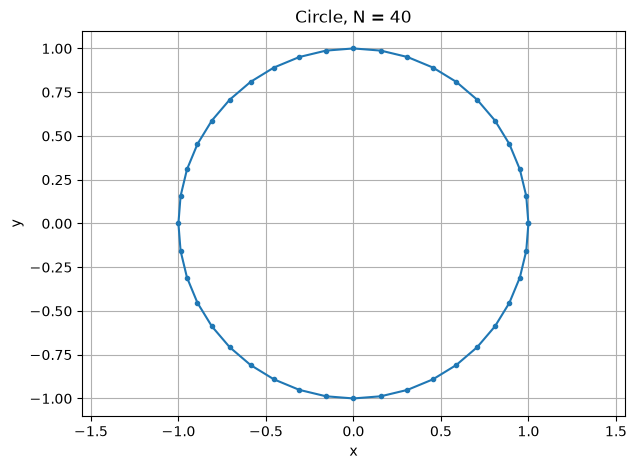

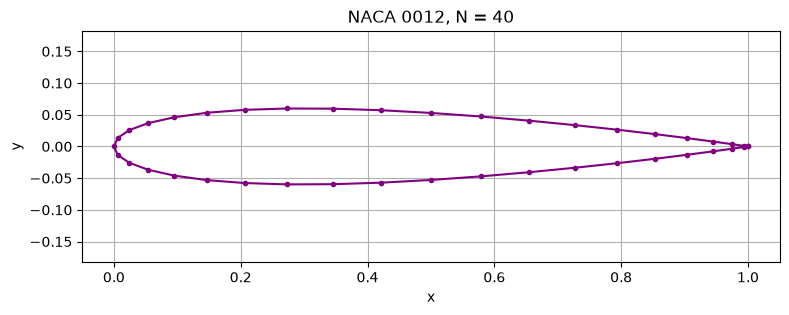

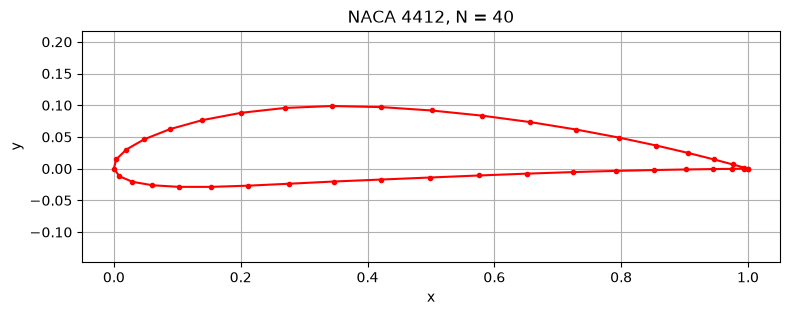

In [5]:
x_circle, y_circle = circle_nodes(40, 1.0)
x_0012, y_0012 = naca4_nodes("0012", 40, "cosine", chord)
x_4412, y_4412 = naca4_nodes("4412", 40, "cosine", chord)

# Now we plot circle first
plt.figure(figsize=(7, 5))

plt.plot(x_circle, y_circle, 'o-', markersize=3)

plt.title("Circle, N = 40")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.grid(True)

plt.show()


#Now, we plot NACA airfoil
plt.figure(figsize=(9, 3))

plt.plot(x_0012, y_0012, 'o-', markersize=3, color="purple")

plt.title("NACA 0012, N = 40")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.grid(True)

plt.show()


#Then we plot a cambered NACA airfoil (The name is already mentioned in the title)
plt.figure(figsize=(9, 3))

plt.plot(x_4412, y_4412, 'o-', markersize=3, color="red")

plt.title("NACA 4412, N = 40")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.grid(True)

plt.show()

In [6]:
def panel_properties(x, y):            # function to calculate panel properties

    N = len(x) - 1                     # This indicates the number of panels

    x_c = np.zeros(N)
    y_c = np.zeros(N)
    S = np.zeros(N)
    theta = np.zeros(N)

    for j in range(N):

        dx = x[j+1] - x[j]
        dy = y[j+1] - y[j]

        x_c[j] = 0.5 * (x[j] + x[j+1])      # control points
        y_c[j] = 0.5 * (y[j] + y[j+1])

        S[j] = np.sqrt(dx**2 + dy**2)       # panel length
        theta[j] = np.arctan2(dy, dx)       # panel angle

    return x_c, y_c, S, theta


x_test, y_test = circle_nodes(8, 1.0)       #Testing

x_c_test, y_c_test, S_test, theta_test = panel_properties(x_test, y_test)

print("Panel lengths:", np.round(S_test, 4))
print("Panel angles (deg):", np.round(np.degrees(theta_test), 2))
print("Sum of panel lengths:", np.sum(S_test))
print("Circumference       :", 2 * np.pi)

Panel lengths: [0.7654 0.7654 0.7654 0.7654 0.7654 0.7654 0.7654 0.7654]
Panel angles (deg): [-112.5 -157.5  157.5  112.5   67.5   22.5  -22.5  -67.5]
Sum of panel lengths: 6.122934917841436
Circumference       : 6.283185307179586


In [7]:
def influence_integrals(i, j, x, y, x_c, y_c, S, theta):    # Basicallly, we define here what will be the influence of control point j on the point i

    # Self influence (control point on the same panel)
    if i == j:

        I1 = np.pi
        I2 = 0.0
        J1 = np.pi * S[j] / 2
        J2 = -S[j]

        return I1, I2, J1, J2

    # Control point in the local coordinates of panel j
    dx = x_c[i] - x[j]
    dy = y_c[i] - y[j]

    xi = dx * np.cos(theta[j]) + dy * np.sin(theta[j])
    eta = -dx * np.sin(theta[j]) + dy * np.cos(theta[j])

    # This will calculate the distance between the two end of the panels
    r1 = np.sqrt(xi**2 + eta**2)
    r2 = np.sqrt((xi - S[j])**2 + eta**2)

    # NOw calculating the Integrals
    I1 = np.arctan2(eta, xi - S[j]) - np.arctan2(eta, xi)
    I2 = np.log(r1 / r2)

    J1 = xi * I1 - eta * I2
    J2 = xi * I2 - S[j] + eta * I1

    return I1, I2, J1, J2


# Testing with a panel from (0,0) to (1,0) and control point at (0.5, 0.5)

x_t = np.array([0.0, 1.0])
y_t = np.array([0.0, 0.0])

x_c_t = np.array([0.5, 0.5])        # The first point is on the panel meanwhile second is the test point
y_c_t = np.array([0.0, 0.5])

S_t = np.array([1.0])
theta_t = np.array([0.0])

I1, I2, J1, J2 = influence_integrals(1, 0, x_t, y_t, x_c_t, y_c_t, S_t, theta_t)

print("Integrals for the test point")
print("I1 =", I1, "   expected:", np.pi / 2)
print("I2 =", I2, "   expected: 0")
print("J1 =", J1, "   expected:", np.pi / 4)
print("J2 =", J2, "   expected:", np.pi / 4 - 1)

I1, I2, J1, J2 = influence_integrals(0, 0, x_t, y_t, x_c_t, y_c_t, S_t, theta_t)

print("\nSelf influence")
print("I1, I2, J1, J2 =", I1, I2, J1, J2)

Integrals for the test point
I1 = 1.5707963267948966    expected: 1.5707963267948966
I2 = 0.0    expected: 0
J1 = 0.7853981633974483    expected: 0.7853981633974483
J2 = -0.21460183660255172    expected: -0.21460183660255172

Self influence
I1, I2, J1, J2 = 3.141592653589793 0.0 1.5707963267948966 -1.0


In [8]:
def vortex_panel_method_0(x, y, alpha_deg, V_inf):      # Making a constant strength vortex panel

    alpha = np.radians(alpha_deg)
    N = len(x) - 1                                      # Now defining the  number of panels

    x_c, y_c, S, theta = panel_properties(x, y)
    chord = np.max(x) - np.min(x)

    A = np.zeros((N, N))
    B = np.zeros((N, N))
    b = np.zeros(N)

 
    for i in range(N):         #Here we are building an influence matrix

        for j in range(N):

            I1, I2, J1, J2 = influence_integrals(i, j, x, y, x_c, y_c, S, theta)

            # velocity in local frame of panel j
            u = I1 / (2 * np.pi)
            w = -I2 / (2 * np.pi)

            # velocity in global frame
            U = u * np.cos(theta[j]) - w * np.sin(theta[j])
            V = u * np.sin(theta[j]) + w * np.cos(theta[j])

            # normal and tangential components at panel i
            A[i, j] = -U * np.sin(theta[i]) + V * np.cos(theta[i])
            B[i, j] = U * np.cos(theta[i]) + V * np.sin(theta[i])

        b[i] = V_inf * np.sin(theta[i] - alpha)

    # Kutta condition replaces the last equation
    A[N-1, :] = 0.0
    A[N-1, 0] = 1.0
    A[N-1, N-1] = 1.0
    b[N-1] = 0.0

    # Solving the system
    gamma = np.linalg.lstsq(A, b, rcond=None)[0]

    Vt = np.zeros(N)
    Cp = np.zeros(N)

    for i in range(N):

        Vt[i] = V_inf * np.cos(theta[i] - alpha) + np.sum(B[i, :] * gamma)
        Cp[i] = 1 - (Vt[i] / V_inf)**2

    Gamma = np.sum(gamma * S)
    Cl = 2 * Gamma / (V_inf * chord)

    return gamma, Cp, Cl, x_c, theta, S

In [9]:
# Test 1: Now testing for the circular cylinder

N_test = 40
x_cyl, y_cyl = circle_nodes(N_test, 1.0)

gamma, Cp, Cl, x_c, theta, S = vortex_panel_method_0(x_cyl, y_cyl, 0.0, V_infinity)

y_c = np.zeros(N_test)
for k in range(N_test):
    y_c[k] = 0.5 * (y_cyl[k] + y_cyl[k+1])

phi = np.arctan2(y_c, x_c)
Cp_exact = 1 - 4 * np.sin(phi)**2

print("Cylinder, N =", N_test)
print("Cl =", Cl, "   expected: 0")
print("RMS error in Cp =", np.sqrt(np.mean((Cp - Cp_exact)**2)))


# Test 2: Now testing for the airfoils (includes symmetric as well as cambered)

print("\nAirfoil results (N = 160, cosine spacing)")
print("Airfoil   alpha   Cl (panel)   Cl (thin airfoil)")

for code in ["0012", "4412"]:

    for alpha_test in [0, 4, 8]:

        x_af, y_af = naca4_nodes(code, 160, "cosine", chord)

        gamma, Cp, Cl, x_c, theta, S = vortex_panel_method_0(x_af, y_af, alpha_test, V_infinity)

        Cl_thin = 2 * np.pi * np.radians(alpha_test)

        print(code, "   ", alpha_test, "     ", round(Cl, 4), "      ", round(Cl_thin, 4))

Cylinder, N = 40
Cl = -4.711508960753008e-15    expected: 0
RMS error in Cp = 5.049867459293721e-15

Airfoil results (N = 160, cosine spacing)
Airfoil   alpha   Cl (panel)   Cl (thin airfoil)
0012     0       -0.0        0.0
0012     4       0.484        0.4386
0012     8       0.9657        0.8773
4412     0       0.5244        0.0
4412     4       1.0038        0.4386
4412     8       1.4783        0.8773


In [10]:
def vortex_panel_method_1(x, y, alpha_deg, V_inf):      # Now function for linear strength vortex panel method

    alpha = np.radians(alpha_deg)
    N = len(x) - 1                                      # number of panels

    x_c, y_c, S, theta = panel_properties(x, y)
    chord = np.max(x) - np.min(x)

    A = np.zeros((N + 1, N + 1))
    B = np.zeros((N, N + 1))
    b = np.zeros(N + 1)

    # Building the influence matrices
    for i in range(N):

        for j in range(N):

            I1, I2, J1, J2 = influence_integrals(i, j, x, y, x_c, y_c, S, theta)

            
            u_a = (I1 - J1 / S[j]) / (2 * np.pi)
            w_a = -(I2 - J2 / S[j]) / (2 * np.pi)

            u_b = (J1 / S[j]) / (2 * np.pi)
            w_b = -(J2 / S[j]) / (2 * np.pi)

            # global velocity
            U_a = u_a * np.cos(theta[j]) - w_a * np.sin(theta[j])
            V_a = u_a * np.sin(theta[j]) + w_a * np.cos(theta[j])

            U_b = u_b * np.cos(theta[j]) - w_b * np.sin(theta[j])
            V_b = u_b * np.sin(theta[j]) + w_b * np.cos(theta[j])

            # adding into column j and column j+1
            A[i, j]   += -U_a * np.sin(theta[i]) + V_a * np.cos(theta[i])
            A[i, j+1] += -U_b * np.sin(theta[i]) + V_b * np.cos(theta[i])

            B[i, j]   += U_a * np.cos(theta[i]) + V_a * np.sin(theta[i])
            B[i, j+1] += U_b * np.cos(theta[i]) + V_b * np.sin(theta[i])

        b[i] = V_inf * np.sin(theta[i] - alpha)

    # Kutta condition as the last equation i.e for the trailing edge
    A[N, 0] = 1.0
    A[N, N] = 1.0
    b[N] = 0.0

    # Solving the system
    gamma = np.linalg.lstsq(A, b, rcond=None)[0]

    
    Vt = np.zeros(N)
    Cp = np.zeros(N)

    for i in range(N):

        Vt[i] = V_inf * np.cos(theta[i] - alpha) + np.sum(B[i, :] * gamma)
        Cp[i] = 1 - (Vt[i] / V_inf)**2

    Gamma = 0.0
    for j in range(N):
        Gamma += S[j] * (gamma[j] + gamma[j+1]) / 2

    Cl = 2 * Gamma / (V_inf * chord)

    return gamma, Cp, Cl, x_c, theta, S

In [11]:
# Test 1: Now testing for Circular cylinder

print("Cylinder, linear strength panels")
print("N      Cl            RMS error in Cp")

for N_test in [20, 40, 80, 160]:

    x_cyl, y_cyl = circle_nodes(N_test, 1.0)

    gamma, Cp, Cl, x_c, theta, S = vortex_panel_method_1(x_cyl, y_cyl, 0.0, V_infinity)

    y_c = np.zeros(N_test)
    for k in range(N_test):
        y_c[k] = 0.5 * (y_cyl[k] + y_cyl[k+1])

    phi = np.arctan2(y_c, x_c)
    Cp_exact = 1 - 4 * np.sin(phi)**2

    rms = np.sqrt(np.mean((Cp - Cp_exact)**2))

    print(N_test, "   ", format(Cl, ".2e"), "   ", format(rms, ".4e"))


# Test 2: Now testing for Symmetric and Cambered airfoils and comparing with the constant strength method

print("\nAirfoil results (N = 160, cosine spacing)")
print("Airfoil   alpha   Cl (linear)   Cl (constant)")

for code in ["0012", "4412"]:

    for alpha_test in [0, 4, 8]:

        x_af, y_af = naca4_nodes(code, 160, "cosine", chord)

        g1, Cp1, Cl_linear, xc1, th1, S1 = vortex_panel_method_1(x_af, y_af, alpha_test, V_infinity)
        g0, Cp0, Cl_const, xc0, th0, S0 = vortex_panel_method_0(x_af, y_af, alpha_test, V_infinity)

        print(code, "   ", alpha_test, "     ", round(Cl_linear, 4), "       ", round(Cl_const, 4))

Cylinder, linear strength panels
N      Cl            RMS error in Cp
20     9.77e-15     1.8590e-01
40     3.64e-13     8.9058e-02
80     -1.16e-14     4.3505e-02
160     3.51e-15     2.1490e-02

Airfoil results (N = 160, cosine spacing)
Airfoil   alpha   Cl (linear)   Cl (constant)
0012     0       0.0         -0.0
0012     4       0.4826         0.484
0012     8       0.9628         0.9657
4412     0       0.518         0.5244
4412     4       0.9992         1.0038
4412     8       1.4757         1.4783


In [12]:
# Now, doing the Convergence study on the circular cylinder

R = 1.0

error_0 = []        # RMS error for constant strength method
error_1 = []        # RMS error for linear strength method
Cl_0 = []
Cl_1 = []

for N_cyl in panel_numbers:

    x_cyl, y_cyl = circle_nodes(N_cyl, R)

    # control points angle
    y_c = np.zeros(N_cyl)
    for k in range(N_cyl):
        y_c[k] = 0.5 * (y_cyl[k] + y_cyl[k+1])

    # Now executing the constant strength function
    gamma0, Cp0, Cl0, x_c0, theta0, S0 = vortex_panel_method_0(x_cyl, y_cyl, 0.0, V_infinity)

    # Now executing the linear strength function
    gamma1, Cp1, Cl1, x_c1, theta1, S1 = vortex_panel_method_1(x_cyl, y_cyl, 0.0, V_infinity)

    phi = np.arctan2(y_c, x_c0)
    Cp_exact = 1 - 4 * np.sin(phi)**2

    error_0.append(np.sqrt(np.mean((Cp0 - Cp_exact)**2)))
    error_1.append(np.sqrt(np.mean((Cp1 - Cp_exact)**2)))

    Cl_0.append(Cl0)
    Cl_1.append(Cl1)


# Now, we display those obtained values

print("N        Constant method        Linear method        Order (linear)")

for k in range(len(panel_numbers)):

    if k == 0:
        order = "   -"
    else:
        order = round(np.log(error_1[k-1] / error_1[k]) / np.log(panel_numbers[k] / panel_numbers[k-1]), 3)

    print(panel_numbers[k], "     ", format(error_0[k], ".3e"), "         ", format(error_1[k], ".3e"), "        ", order)

print("\nOverall order of convergence (linear method) from slope of log-log fit:")
slope = np.polyfit(np.log(panel_numbers), np.log(error_1), 1)[0]
print("p =", round(-slope, 3))

print("\nMaximum |Cl| over all runs (exact value is 0):")
print("Constant method:", np.max(np.abs(Cl_0)))
print("Linear method  :", np.max(np.abs(Cl_1)))

N        Constant method        Linear method        Order (linear)
20       6.822e-15           1.859e-01             -
40       5.050e-15           8.906e-02          1.062
80       4.454e-14           4.350e-02          1.034
160       3.754e-14           2.149e-02          1.018
320       1.763e-13           1.068e-02          1.009

Overall order of convergence (linear method) from slope of log-log fit:
p = 1.029

Maximum |Cl| over all runs (exact value is 0):
Constant method: 3.241851231905457e-13
Linear method  : 3.640386603276369e-13


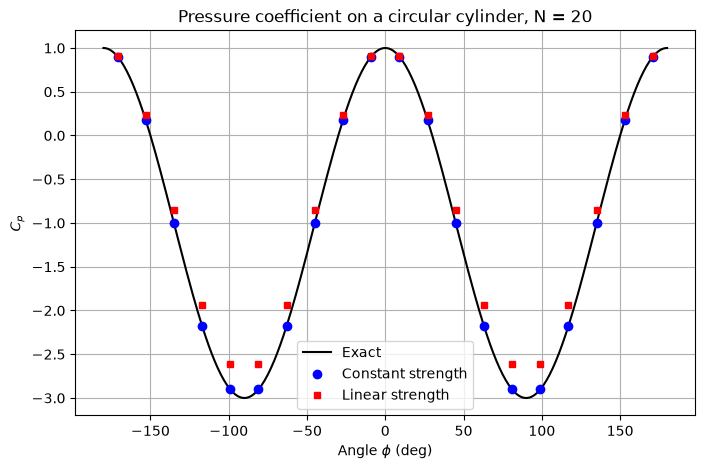

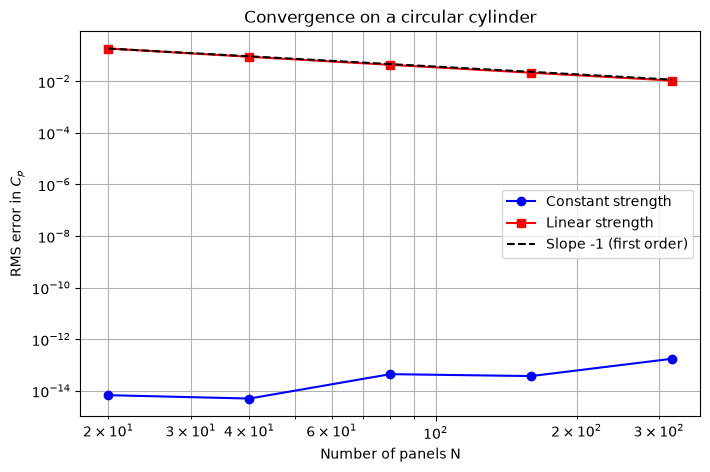

In [13]:
# Plot 1: Cp distribution over the angle (phi) for N = 20

N_plot = 20

x_cyl, y_cyl = circle_nodes(N_plot, R)

y_c = np.zeros(N_plot)
for k in range(N_plot):
    y_c[k] = 0.5 * (y_cyl[k] + y_cyl[k+1])

gamma0, Cp0, Cl0, x_c0, theta0, S0 = vortex_panel_method_0(x_cyl, y_cyl, 0.0, V_infinity)
gamma1, Cp1, Cl1, x_c1, theta1, S1 = vortex_panel_method_1(x_cyl, y_cyl, 0.0, V_infinity)

phi_deg = np.degrees(np.arctan2(y_c, x_c0))

phi_fine = np.linspace(-180, 180, 361)
Cp_fine = 1 - 4 * np.sin(np.radians(phi_fine))**2

plt.figure(figsize=(8, 5))

plt.plot(phi_fine, Cp_fine, 'k-', label="Exact")
plt.plot(phi_deg, Cp0, 'bo', markersize=6, label="Constant strength")
plt.plot(phi_deg, Cp1, 'rs', markersize=5, label="Linear strength")

plt.xlabel("Angle $\\phi$ (deg)")
plt.ylabel("$C_p$")
plt.title("Pressure coefficient on a circular cylinder, N = 20")
plt.legend()
plt.grid(True)
plt.show()


# Plot 2: convergence of the circular cylinder

reference = []
for k in range(len(panel_numbers)):
    reference.append(error_1[0] * (panel_numbers[0] / panel_numbers[k]))     # slope -1 line

plt.figure(figsize=(8, 5))

plt.loglog(panel_numbers, error_0, 'bo-', label="Constant strength")
plt.loglog(panel_numbers, error_1, 'rs-', label="Linear strength")
plt.loglog(panel_numbers, reference, 'k--', label="Slope -1 (first order)")

plt.xlabel("Number of panels N")
plt.ylabel("RMS error in $C_p$")
plt.title("Convergence on a circular cylinder")
plt.legend()
plt.grid(True, which="both")
plt.show()